In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sys  # tool to tell Python where to look for files

sys.path.append("..")

from src.time_analysis import add_time_columns, summarize_revenue

df = pd.read_csv("../data/ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [2]:
# Check column names

df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
    .str.lower()
)

In [3]:
# Look at the structure

print("Rows and columns:", df.shape)
df.info()  # show column names, data types and non-empty counts

Rows and columns: (2500, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


In [4]:
# Check data quality

print("Missing values per column:")
print(df.isna().sum()) # count empty cells in each column

print("Duplicate rows:", df.duplicated().sum()) # count rows that are exact copies
print("Duplicate order_id:", df["order_id"].duplicated().sum()) # each order_id should appear only once

revenue_difference = (df["price"] * df["units"] - df["revenue"]).abs() # gap between price*units and revenue (always positive)
print("Max difference between price*units and revenue:", revenue_difference.max())

Missing values per column:
order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Duplicate rows: 0
Duplicate order_id: 0
Max difference between price*units and revenue: 1.8189894035458565e-12


In [5]:
# Fix the date column and check missing dates

print("Before:", df["date"].dtype) # show the type before converting

df["date"] = pd.to_datetime(df["date"]) # turn text into real dates
df = df.sort_values("date").reset_index(drop=True) # sort oldest to newest and restart row numbers at 0

print("After:", df["date"].dtype)
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

expected_days = (df["date"].max() - df["date"].min()).days + 1  # days from first to last date
print("Days with sales:", df["date"].nunique(), "of", expected_days)

Before: str
After: datetime64[us]
First date: 2024-01-01 00:00:00
Last date: 2024-06-30 00:00:00
Days with sales: 182 of 182


In [6]:
df = add_time_columns(df)  # add month and weekday columns in one step
df[["date", "month_number", "month_name", "weekday_number", "weekday_name"]].head()

,date,month_number,month_name,weekday_number,weekday_name
0,2024-01-01,1,January,1,Monday
1,2024-01-01,1,January,1,Monday
2,2024-01-01,1,January,1,Monday
3,2024-01-01,1,January,1,Monday
4,2024-01-01,1,January,1,Monday


In [7]:
# Sales by month

monthly_summary = summarize_revenue(df, ["month_number", "month_name"])
monthly_summary.drop(columns = "month_number")  # show without month number

,month_name,total_revenue,total_units,order_count,average_order_value
0,January,664083.32,1353,445,1492.32
1,February,548462.03,1097,357,1536.31
2,March,487602.00,1116,411,1186.38
3,April,580194.83,1305,432,1343.04
4,May,632165.16,1367,433,1459.97
5,June,590259.89,1225,422,1398.72


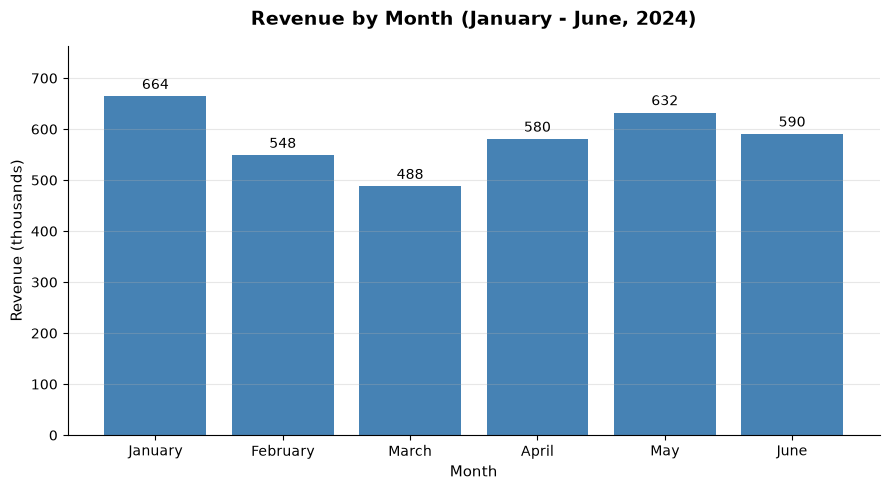

In [8]:
fig, ax = plt.subplots(figsize = (9, 5))

revenue_in_thousands = monthly_summary["total_revenue"] / 1000  # show revenue in thousands so the numbers are short

bars = ax.bar(monthly_summary["month_name"], revenue_in_thousands, color="steelblue")
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=10)  # write the value on top of each bar)

ax.set_title("Revenue by Month (January - June, 2024)", fontsize=14, fontweight = "bold", pad=15)  
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Revenue (thousands)", fontsize=11)
ax.set_ylim(0, revenue_in_thousands.max() *1.15) # leave space above the tallest bar (axis still starts at 0)
ax.grid(axis ="y", alpha=0.3)  # light horizontal grid lines behind the bars

ax.spines["top"].set_visible(False)  # remove the top border
ax.spines["right"].set_visible(False)  # remove the right border

fig.tight_layout()  # fit everything inside the picture
plt.show()

This chart shows total revenue for each month. January is the highest (about 664k) and March is the lowest (about 488k).

In [9]:
# Sales by weekday

weekday_summary = summarize_revenue(df, ["weekday_number", "weekday_name"])
weekday_summary.drop(columns = "weekday_number")  # show without weekday number

,weekday_name,total_revenue,total_units,order_count,average_order_value
0,Monday,527263.73,1115,368,1432.78
1,Tuesday,512978.35,1037,354,1449.09
2,Wednesday,502661.61,1063,346,1452.78
3,Thursday,518871.71,1098,361,1437.32
4,Friday,501396.53,1082,357,1404.47
5,Saturday,481483.77,1052,355,1356.29
6,Sunday,458111.53,1016,359,1276.08


In [10]:
# Sales by week

weekly_summary = (
    df.resample("W", on="date")  # cut the timeline into weeks (Monday to Sunday) using the date column
    .agg(
        total_revenue = ("revenue", "sum"),
        total_units = ("units", "sum"),
        order_count = ("order_id", "count")
    )
    .reset_index()  # turn the week labels back into normal columns
    .rename(columns = {"date": "week_ending"})  # rename it: the label is the Sunday that ends each week
)

weekly_summary["average_order_value"] = weekly_summary["total_revenue"] / weekly_summary["order_count"]
weekly_summary = weekly_summary.round({"total_revenue": 2,"average_order_value": 2})  # round only these columns

weekly_summary["week_start"] = weekly_summary["week_ending"] - pd.Timedelta(days=6)  # the Monday that starts each week (Sunday minus 6 days)
weekly_summary["week_label"] = (
    weekly_summary["week_start"].dt.strftime("%b %d")  # start date as short text
    + " - "
    + weekly_summary["week_ending"].dt.strftime("%b %d, %Y")
)

print("Number of weeks:", len(weekly_summary))
weekly_summary[["week_label", "total_revenue", "total_units", "order_count", "average_order_value"]].head()

Number of weeks: 26


,week_label,total_revenue,total_units,order_count,average_order_value
0,"Jan 01 - Jan 07, 2024",161119.04,326,108,1491.84
1,"Jan 08 - Jan 14, 2024",136568.68,265,81,1686.03
2,"Jan 15 - Jan 21, 2024",147225.11,319,104,1415.63
3,"Jan 22 - Jan 28, 2024",165832.80,328,108,1535.49
4,"Jan 29 - Feb 04, 2024",124154.34,247,89,1394.99


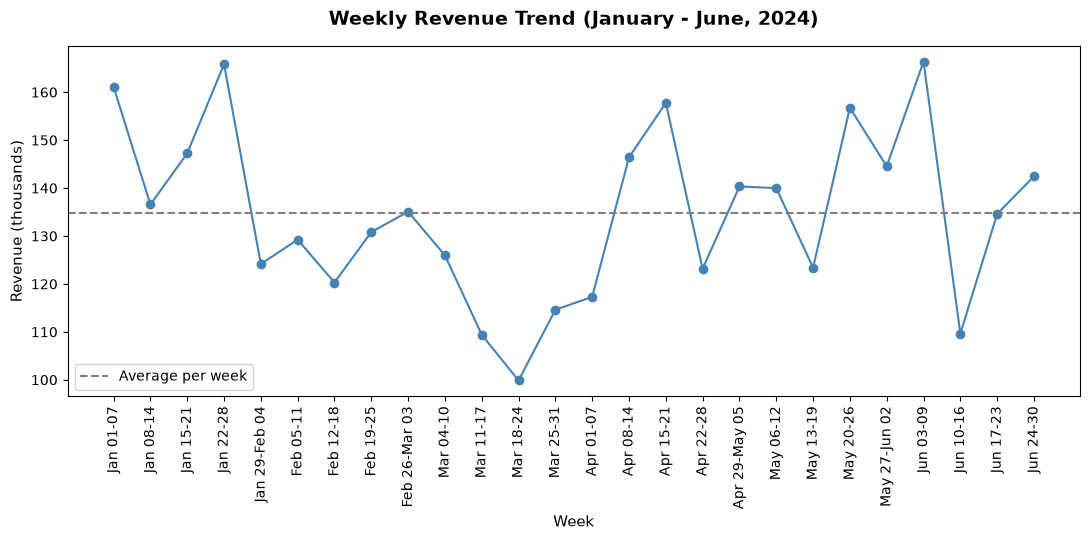

In [11]:
same_month = weekly_summary["week_start"].dt.month == weekly_summary["week_ending"].dt.month  # True if the week starts and ends in the same month
end_text = weekly_summary["week_ending"].dt.strftime("%d").where(same_month, weekly_summary["week_ending"].dt.strftime("%b %d"))  # end date: day only, or month + day when the month changes
weekly_summary["week_short"] = weekly_summary["week_start"].dt.strftime("%b %d") + "-" + end_text  # short label like Jan 01-07
revenue_in_thousands = weekly_summary["total_revenue"] / 1000  # show revenue in thousands so the numbers are short

fig, ax = plt.subplots(figsize = (11, 5.5))
ax.plot(weekly_summary["week_short"], revenue_in_thousands, color="steelblue", marker="o")  # line with a dot for each week
ax.axhline(revenue_in_thousands.mean(), color="gray", linestyle="--", label="Average per week")  # dashed average line

ax.set_title("Weekly Revenue Trend (January - June, 2024)", fontsize=14, fontweight = "bold", pad=15)  
ax.set_xlabel("Week", fontsize=11)
ax.set_ylabel("Revenue (thousands)", fontsize=11)
ax.tick_params(axis="x", rotation=90)  # turn the labels so they do not overlap
ax.legend()  # show the label of the average line

fig.tight_layout()  # fit everything inside the picture
plt.show()

This chart shows total revenue for each week. Revenue was lowest in the week of Mar 18 (about 100k) and stayed below the weekly average for five weeks in a row in March.